# Grouped vs flat tables

Issue [#123](https://github.com/adkipnis/mixedbench/issues/123).

MixedBench's datasets are grouped tables, each with a documented mixed model whose grouping factors carry random effects.<br>
Their sources also ship flat tables, which no documented model fits with a random effect and whose rows no column groups.<br>
Both are loaded and measured by the same code, but whether they differ beyond the grouping has had no data.

This experiment compares the two, one table at a time.

- **Grouped:** each dataset's columns but its first documented model's response, binomial trials, grouping factors and ignored columns (e.g. ids, weights), `registry` below.
- **Flat:** every column but the id columns (categoricals whose values are all distinct) and the response, where the documentation names one.
- **Sizes:** rows, columns, design columns (a categorical with K levels counts K − 1) and the design's condition index.
- **Type mix:** the shares of continuous, binary, categorical and ordered columns, and the median K of the categorical and ordered ones.
- **Column medians:** per [column statistic](https://github.com/adkipnis/mixedbench/blob/main/docs/registry.md#dimensionscsv-columnscsv-column_factorscsv-and-factor_pairscsv), its median over the table's columns.
- **Test:** the two-sided Mann–Whitney U test per statistic, over the tables where it is defined.
- **Effect size:** the rank-biserial correlation r, the probability that a grouped table lies above a flat one minus the reverse.

`run.py` reads the measured files of mixedbench 1.0.10 and writes `tests.csv`, which this notebook reads.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

tests = pd.read_csv('tests.csv')
columns = ['n_registry', 'n_flat', 'median_registry', 'median_flat', 'rank_biserial', 'p']
tests[tests['flat'] == 'all'].set_index('statistic')[columns]

,n_registry,n_flat,median_registry,median_flat,rank_biserial,p
statistic,,,,,,
n_obs,649,696,456.0000,75.5000,0.4369,1.066563e-43
n_columns,649,696,3.0000,4.0000,-0.2015,1.123369e-10
d_all,649,696,4.0000,4.0000,-0.0796,1.115948e-02
condition_all,618,673,3.9839,5.4230,-0.1577,9.104592e-07
continuous_share,606,688,0.5000,0.8571,-0.4171,7.931129e-40
binary_share,606,688,0.2500,0.0000,0.2630,4.236221e-18
categorical_share,606,688,0.0000,0.0000,0.1770,2.919767e-11
ordered_share,606,688,0.0000,0.0000,0.0657,2.798538e-09
K,278,173,4.0000,4.0000,-0.0555,3.125910e-01


## Effect sizes

Per statistic, r over all flat tables and over those whose documentation names a response.<br>
A flat table without a named response may keep its outcome among its columns, which a grouped table never counts.

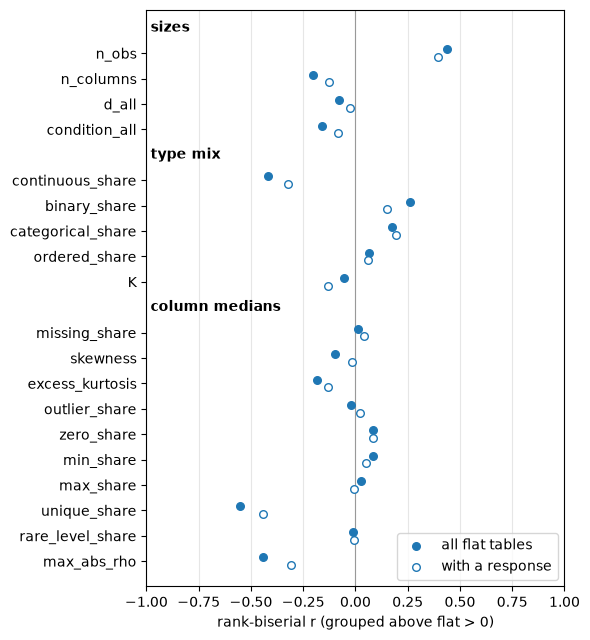

In [2]:
BLOCKS = {'sizes': 4, 'type mix': 5, 'column medians': 10}  # consecutive statistics of tests.csv
SIDES = {  # label, vertical offset, marker face
    'all': ('all flat tables', -0.15, 'C0'),
    'response': ('with a response', 0.15, 'white'),
}

statistics = tests['statistic'].unique()
r = tests.pivot(index='statistic', columns='flat', values='rank_biserial').loc[statistics]
y = []  # a row per statistic, a heading row above each block
headings = {}
row = 0
for name, count in BLOCKS.items():
    headings[name] = row
    y.extend(range(row + 1, row + 1 + count))
    row += count + 1
y = np.array(y)

fig, ax = plt.subplots(figsize=(6, 6.5))
ax.axvline(0, color='0.6', linewidth=0.8)
for side, (label, offset, face) in SIDES.items():
    ax.scatter(r[side], y + offset, s=30, color='C0', facecolor=face, label=label, zorder=3)
for name, row in headings.items():
    ax.text(-0.98, row, name, va='center', fontweight='bold')
ax.set(
    xlim=(-1, 1),
    ylim=(y[-1] + 1, -0.7),
    yticks=y,
    yticklabels=statistics,
    xlabel='rank-biserial r (grouped above flat > 0)',
)
ax.grid(axis='x', color='0.9')
ax.set_axisbelow(True)
ax.legend(loc='lower right')
fig.tight_layout()
fig.savefig('effects.pdf')

## Finding

**Grouped and flat tables differ most in size, type mix and how distinct their values are.**<br>
Grouped tables have more rows and more binary and categorical columns, flat tables more continuous ones.<br>
Flat tables' columns hold more distinct values and correlate more strongly, though fewer rows alone raise both.<br>
Skewness, outliers, extremes and missing values barely differ.<br>
Over the flat tables with a response, every large effect keeps its sign but shrinks.